In [1]:
# importing libraries for computer vision
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from PIL import Image
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
import joblib
import warnings
warnings.filterwarnings('ignore')

print('All libraries imported!')

All libraries imported!


In [3]:
# path to brain CT scan images
data_dir = r'C:\Users\Ar\Desktop\multi-model-strok-prediction\data\brain_dataset'

# checking classes
classes = os.listdir(data_dir)
print('Classes found:', classes)

# counting images per class
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    if os.path.isdir(cls_path):
        count = len(os.listdir(cls_path))
        print(f'{cls}: {count} images')

Classes found: ['Normal', 'Stroke']
Normal: 1551 images
Stroke: 950 images


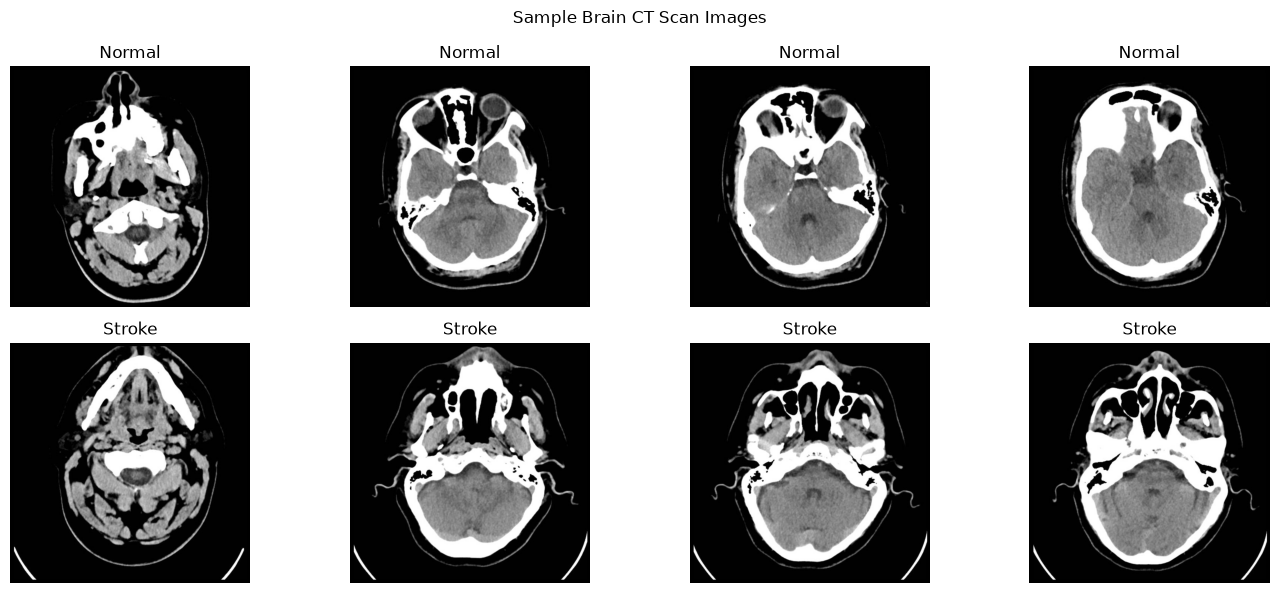

In [4]:
# showing sample images from each class
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for idx, cls in enumerate(classes[:2]):
    cls_path = os.path.join(data_dir, cls)
    images_list = os.listdir(cls_path)[:4]
    
    for j, img_name in enumerate(images_list):
        img_path = os.path.join(cls_path, img_name)
        img = Image.open(img_path).convert('RGB')
        axes[idx][j].imshow(img)
        axes[idx][j].set_title(cls)
        axes[idx][j].axis('off')

plt.suptitle('Sample Brain CT Scan Images')
plt.tight_layout()
plt.show()

In [5]:
# extracting features from images
# we resize each image and flatten pixel values as features
# this is classical CV approach without deep learning

def extract_features(data_dir, img_size=(64, 64)):
    features = []
    labels = []
    class_names = sorted(os.listdir(data_dir))
    
    print('Extracting features...')
    
    for label, cls in enumerate(class_names):
        cls_path = os.path.join(data_dir, cls)
        if not os.path.isdir(cls_path):
            continue
            
        images_list = os.listdir(cls_path)
        print(f'Processing {cls}: {len(images_list)} images')
        
        for img_name in images_list:
            try:
                img_path = os.path.join(cls_path, img_name)
                img = Image.open(img_path).convert('L')  # grayscale
                img = img.resize(img_size)
                img_array = np.array(img).flatten()  # flatten to 1D
                features.append(img_array)
                labels.append(label)
            except:
                continue
    
    print(f'Total images loaded: {len(features)}')
    print(f'Classes: {class_names}')
    return np.array(features), np.array(labels), class_names

X_img, y_img, class_names = extract_features(data_dir)
print('Feature shape:', X_img.shape)
print('Labels shape:', y_img.shape)
print('Class distribution:', np.unique(y_img, return_counts=True))

Extracting features...
Processing Normal: 1551 images
Processing Stroke: 950 images
Total images loaded: 2501
Classes: ['Normal', 'Stroke']
Feature shape: (2501, 4096)
Labels shape: (2501,)
Class distribution: (array([0, 1]), array([1551,  950], dtype=int64))


In [6]:
# splitting image data
X_img_train, X_img_test, y_img_train, y_img_test = train_test_split(
    X_img, y_img, test_size=0.2, random_state=42, stratify=y_img)

# scaling pixel values
img_scaler = StandardScaler()
X_img_train_scaled = img_scaler.fit_transform(X_img_train)
X_img_test_scaled = img_scaler.transform(X_img_test)

print('Training images:', X_img_train_scaled.shape[0])
print('Testing images:', X_img_test_scaled.shape[0])

Training images: 2000
Testing images: 501


In [7]:
# training Random Forest on image features
# Random Forest works well for image classification
model_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print('Training CV model on brain CT scans...')
model_cv.fit(X_img_train_scaled, y_img_train)
print('Training complete!')

Training CV model on brain CT scans...
Training complete!


In [8]:
# predictions
y_pred_cv = model_cv.predict(X_img_test_scaled)
y_pred_proba_cv = model_cv.predict_proba(X_img_test_scaled)[:, 1]

print('Computer Vision Results:')
print('Accuracy: ', round(accuracy_score(y_img_test, y_pred_cv) * 100, 2), '%')
print('Precision:', round(precision_score(y_img_test, y_pred_cv) * 100, 2), '%')
print('Recall:   ', round(recall_score(y_img_test, y_pred_cv) * 100, 2), '%')
print('F1 Score: ', round(f1_score(y_img_test, y_pred_cv) * 100, 2), '%')
print('AUC:      ', round(roc_auc_score(y_img_test, y_pred_proba_cv), 3))

Computer Vision Results:
Accuracy:  98.2 %
Precision: 100.0 %
Recall:    95.26 %
F1 Score:  97.57 %
AUC:       0.994


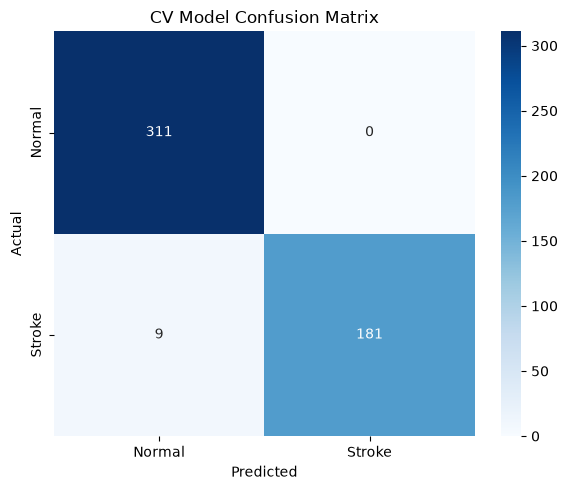

In [9]:
cm_cv = confusion_matrix(y_img_test, y_pred_cv)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('CV Model Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

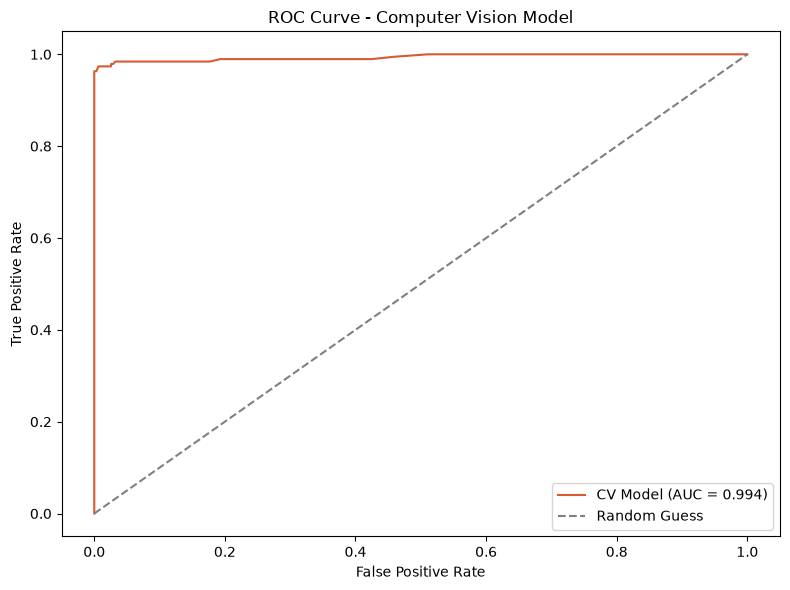

In [10]:
fpr_cv, tpr_cv, _ = roc_curve(y_img_test, y_pred_proba_cv)
auc_cv = roc_auc_score(y_img_test, y_pred_proba_cv)

plt.figure(figsize=(8, 6))
plt.plot(fpr_cv, tpr_cv, color='#D85A30',
         label=f'CV Model (AUC = {round(auc_cv, 3)})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Computer Vision Model')
plt.legend()
plt.tight_layout()
plt.show()

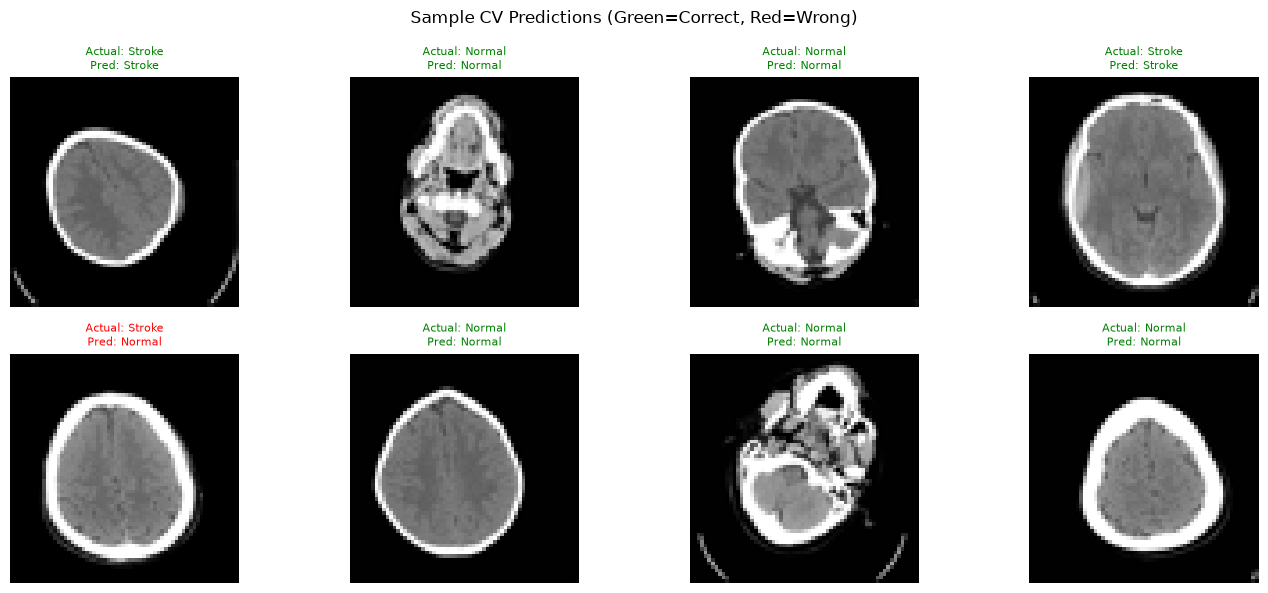

In [11]:
# showing sample predictions on test images
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()

for i in range(8):
    # getting original image
    test_idx = i * 5
    
    # finding which class and image it belongs to
    pred_label = y_pred_cv[test_idx]
    actual_label = y_img_test[test_idx]
    
    # reshaping flattened image back to 64x64
    img_show = X_img_test[test_idx].reshape(64, 64)
    
    axes[i].imshow(img_show, cmap='gray')
    axes[i].set_title(
        f'Actual: {class_names[actual_label]}\nPred: {class_names[pred_label]}',
        color='green' if pred_label == actual_label else 'red',
        fontsize=8
    )
    axes[i].axis('off')

plt.suptitle('Sample CV Predictions (Green=Correct, Red=Wrong)')
plt.tight_layout()
plt.show()

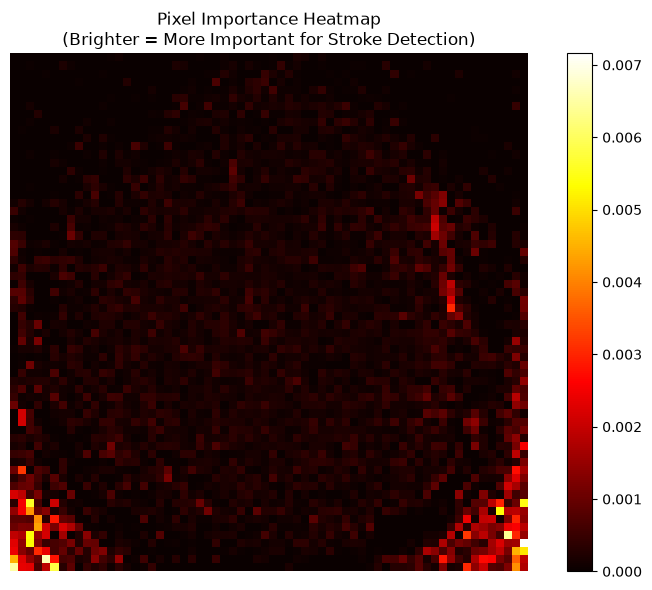

In [12]:
# top pixels most important for prediction
importances = model_cv.feature_importances_
importance_img = importances.reshape(64, 64)

plt.figure(figsize=(8, 6))
plt.imshow(importance_img, cmap='hot')
plt.colorbar()
plt.title('Pixel Importance Heatmap\n(Brighter = More Important for Stroke Detection)')
plt.axis('off')
plt.tight_layout()
plt.show()

In [15]:
# final comparison of all 3 models
ml_model_final = joblib.load(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\best_ml_model.pkl')
ml_scaler_final = joblib.load(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\scaler.pkl')
dl_model_final = joblib.load(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\dl_model.pkl')

# loading stroke tabular test data
import pandas as pd
df = pd.read_csv(r"C:\Users\Ar\Desktop\multi-model-strok-prediction\data\stroke-dataset.csv")
df['bmi'] = df['bmi'].fillna(df['bmi'].median())
df = df.drop(['id'], axis=1)
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type',
                                          'Residence_type', 'smoking_status'],
                             drop_first=True)
X_tab = df_encoded.drop('stroke', axis=1)
y_tab = df_encoded['stroke']
_, X_tab_test, _, y_tab_test = train_test_split(
    X_tab, y_tab, test_size=0.2, random_state=42, stratify=y_tab)

X_tab_test_scaled = ml_scaler_final.transform(X_tab_test)

# all predictions
ml_pred_final = ml_model_final.predict(X_tab_test_scaled)
dl_pred_final = dl_model_final.predict(X_tab_test_scaled)

final_comparison = {
    'Model': ['XGBoost (ML)', 'Neural Network (DL)', 'CV Model (Brain Scans)'],
    'Type': ['Machine Learning', 'Deep Learning', 'Computer Vision'],
    'Accuracy': [
        round(accuracy_score(y_tab_test, ml_pred_final) * 100, 2),
        round(accuracy_score(y_tab_test, dl_pred_final) * 100, 2),
        round(accuracy_score(y_img_test, y_pred_cv) * 100, 2)
    ],
    'AUC': [
        round(roc_auc_score(y_tab_test,
              ml_model_final.predict_proba(X_tab_test_scaled)[:, 1]), 3),
        round(roc_auc_score(y_tab_test,
              dl_model_final.predict_proba(X_tab_test_scaled)[:, 1]), 3),
        round(roc_auc_score(y_img_test, y_pred_proba_cv), 3)
    ]
}

final_df = pd.DataFrame(final_comparison)
print('FINAL COMPARISON — ALL 3 MODELS:')
print(final_df)

FINAL COMPARISON — ALL 3 MODELS:
                    Model              Type  Accuracy    AUC
0            XGBoost (ML)  Machine Learning     93.64  0.786
1     Neural Network (DL)     Deep Learning     86.89  0.766
2  CV Model (Brain Scans)   Computer Vision     98.20  0.994


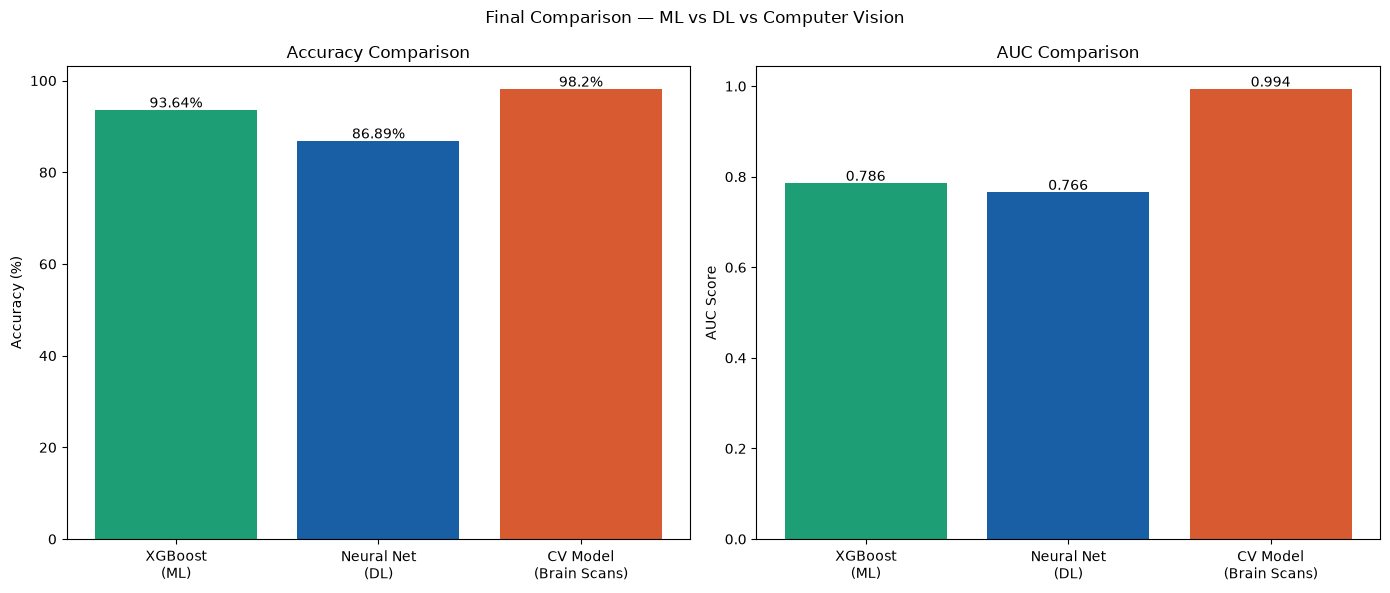

In [16]:
# bar chart of all 3 models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

models_names = ['XGBoost\n(ML)', 'Neural Net\n(DL)', 'CV Model\n(Brain Scans)']
accuracies = final_df['Accuracy'].tolist()
aucs = final_df['AUC'].tolist()
colors = ['#1D9E75', '#185FA5', '#D85A30']

ax1.bar(models_names, accuracies, color=colors)
ax1.set_title('Accuracy Comparison')
ax1.set_ylabel('Accuracy (%)')
for i, v in enumerate(accuracies):
    ax1.text(i, v + 0.5, f'{v}%', ha='center', fontsize=10)

ax2.bar(models_names, aucs, color=colors)
ax2.set_title('AUC Comparison')
ax2.set_ylabel('AUC Score')
for i, v in enumerate(aucs):
    ax2.text(i, v + 0.005, f'{v}', ha='center', fontsize=10)

plt.suptitle('Final Comparison — ML vs DL vs Computer Vision')
plt.tight_layout()
plt.show()

In [17]:
# saving CV model
joblib.dump(model_cv,
            r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\cv_model.pkl')
joblib.dump(img_scaler,
            r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\img_scaler.pkl')
print('CV model saved!')
print('Image scaler saved!')

CV model saved!
Image scaler saved!
